In [ ]:
!pip install opencv-python
!pip install scipy-python
!pip install ipympl

In [ ]:
%matplotlib ipympl

In [ ]:
#part 1.1: Convolution with 4 for loops
import numpy as np
import matplotlib.pyplot as plt
import cv2

img = cv2.imread(r"C:\Users\Muhammad Muneeb\Desktop\Documents\Masters\SYDE 671\Assignment 2\Me.jpeg")
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

kernel = np.ones((9, 9), dtype=np.float32) / 81.0

def convolve_with_4forloops(img, kernel):
    kernel_h, kernel_w = kernel.shape
    img_h, img_w = img.shape

    pad_h = kernel_h // 2
    pad_w = kernel_w // 2

    padded_img = np.pad(img, ((pad_h, pad_h), (pad_w, pad_w)), mode = 'constant', constant_values = 0)

    flip_kernel = np.flip(np.flip(kernel, axis = 0), axis = 1)

    output = np.zeros_like(img, dtype=np.float32)

    for i in range(img_h):
        for j in range(img_w):
            pixel_sum = 0.0

            for k in range(kernel_h):
                for l in range(kernel_w):
                    img_val = padded_img[i + k, j + l]
                    kernel_val = flip_kernel[k, l]
                    pixel_sum += img_val * kernel_val

            output[i, j] = pixel_sum
            
    return output

result = convolve_with_4forloops(img, kernel)
plt.figure(figsize=(10,5))

plt.subplot(1, 2, 1)
plt.title('Original Greyscale')
plt.imshow(img, cmap = 'gray')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title('Filtered (Blurred)')
plt.imshow(result, cmap='gray')
plt.axis('off')

plt.show

In [ ]:
#part 1.1: Convolution with 4 for loops
import numpy as np
import matplotlib.pyplot as plt
import cv2

img = cv2.imread(r"C:\Users\Muhammad Muneeb\Desktop\Documents\Masters\SYDE 671\Assignment 2\Me.jpeg")
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

kernel = np.ones((9, 9), dtype=np.float32) / 81.0

def convolve_with_4forloops(img, kernel):
    kernel_h, kernel_w = kernel.shape
    img_h, img_w = img.shape

    pad_h = kernel_h // 2
    pad_w = kernel_w // 2

    padded_img = np.pad(img, ((pad_h, pad_h), (pad_w, pad_w)), mode = 'constant', constant_values = 0)

    flip_kernel = np.flip(np.flip(kernel, axis = 0), axis = 1)

    output = np.zeros_like(img, dtype=np.float32)

    for i in range(img_h):
        for j in range(img_w):
            pixel_sum = 0.0

            for k in range(kernel_h):
                for l in range(kernel_w):
                    img_val = padded_img[i + k, j + l]
                    kernel_val = flip_kernel[k, l]
                    pixel_sum += img_val * kernel_val

            output[i, j] = pixel_sum
            
    return output

result = convolve_with_4forloops(img, kernel)
plt.figure(figsize=(10,5))

plt.subplot(1, 2, 1)
plt.title('Original Greyscale')
plt.imshow(img, cmap = 'gray')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title('Filtered (Blurred)')
plt.imshow(result, cmap='gray')
plt.axis('off')

plt.show()

In [ ]:
#part 1.1: Convolution with 2 for loops
import numpy as np
import matplotlib.pyplot as plt
import cv2

img = cv2.imread(r"C:\Users\Muhammad Muneeb\Desktop\Documents\Masters\SYDE 671\Assignment 2\Me.jpeg")
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

kernel = np.ones((9, 9), dtype=np.float32) / 81.0

def convolve_with_2forloops(img, kernel):
    kernel_h, kernel_w = kernel.shape
    img_h, img_w = img.shape

    pad_h = kernel_h // 2
    pad_w = kernel_w // 2

    padded_img = np.pad(img, ((pad_h, pad_h), (pad_w, pad_w)), mode = 'constant', constant_values = 0)

    flip_kernel = np.flip(np.flip(kernel, axis = 0), axis = 1)

    output = np.zeros_like(img, dtype=np.float32)

    for i in range(img_h):
        for j in range(img_w):
            roi = padded_img[i : i + kernel_h, j : j + kernel_w]
            output[i, j] = np.sum(roi * flip_kernel)
            
    return output

result = convolve_with_2forloops(img, kernel)
plt.figure(figsize=(10,5))

plt.subplot(1, 2, 1)
plt.title('Original Greyscale')
plt.imshow(img, cmap = 'gray')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title('Filtered (Blurred)')
plt.imshow(result, cmap='gray')
plt.axis('off')

plt.show()

In [ ]:
#part 1.1: Convolution with scipy
import numpy as np
import matplotlib.pyplot as plt
import cv2
from scipy.signal import convolve2d

img = cv2.imread(r"C:\Users\Muhammad Muneeb\Desktop\Documents\Masters\SYDE 671\Assignment 2\Me.jpeg")
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

kernel = np.ones((9, 9), dtype=np.float32) / 81.0

result = convolve2d(img, kernel)

result = convolve_with_2forloops(img, kernel)
plt.figure(figsize=(10,5))

plt.subplot(1, 2, 1)
plt.title('Original Greyscale')
plt.imshow(img, cmap = 'gray')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title('Filtered (Blurred)')
plt.imshow(result, cmap='gray')
plt.axis('off')

plt.show()

In [ ]:
#part 1.1: Convolution with diffeence operators
import numpy as np
import matplotlib.pyplot as plt
import cv2
from scipy.signal import convolve2d

img = cv2.imread(r"C:\Users\Muhammad Muneeb\Desktop\Documents\Masters\SYDE 671\Assignment 2\Me.jpeg")
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

dx = [[1, 0, -1]]
dy = [[1],
      [0],
      [-1]
     ]

grad_x = convolve2d(img, dx, mode='same', boundary='fill', fillvalue=0)
grad_y = convolve2d(img, dy, mode='same', boundary='fill', fillvalue=0)

grad_mag = np.sqrt(grad_x**2 + grad_y**2)

plt.figure(figsize=(10,5))

plt.subplot(1, 2, 1)
plt.title('Original Greyscale')
plt.imshow(img, cmap = 'gray')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title('Filtered (Blurred)')
plt.imshow(grad_mag, cmap='gray')
plt.axis('off')
plt.show

In [ ]:
#1.2 Finite diference operator
import numpy as np
import matplotlib.pyplot as plt
import cv2
from scipy.signal import convolve2d

img = cv2.imread(r'C:\Users\Muhammad Muneeb\Desktop\Documents\Masters\SYDE 671\Assignment 2\hybrid\cameraman.jpeg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

dx = [[1, 0, -1]]
dy = [[1],
      [0],
      [-1]
     ]

grad_x = convolve2d(img, dx, mode='same', boundary='fill', fillvalue=0)
grad_y = convolve2d(img, dy, mode='same', boundary='fill', fillvalue=0)
grad_mag = np.sqrt(grad_x**2 + grad_y**2)

plt.figure(figsize = (5, 5))
plt.subplot(2, 2, 1)
plt.title('Original Greyscale')
plt.imshow(img)
plt.axis('off')

plt.subplot(2, 2, 2)
plt.title('Partial derivative dx')
plt.imshow(grad_x)
plt.axis('off')

plt.subplot(2, 2, 3)
plt.title('Partial derivative dy')
plt.imshow(grad_y)
plt.axis('off')

plt.subplot(2, 2, 4)
plt.title('magnitude of dx and dy')
plt.imshow(grad_mag)
plt.axis('off')


threshold = [20, 30, 40, 50, 60, 70, 80, 90]

plt.figure(figsize= (16, 8))
for i, j in enumerate (threshold, start=1):
    binarized_grad_mag = (grad_mag >= j) * 255

    plt.subplot(2, 4, i)
    plt.title(f'Threshold: {j}')
    plt.imshow(binarized_grad_mag)
    plt.axis('off')

plt.show() 

In [ ]:
#1.3 Derivative of Gaussian (DoG) Filter
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cv2
from scipy.signal import convolve2d

img = cv2.imread(r'C:\Users\Muhammad Muneeb\Desktop\Documents\Masters\SYDE 671\Assignment 2\hybrid\cameraman.jpeg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

kernel_size = 5
sigma = 1

gaussian_1d = cv2.getGaussianKernel(ksize = kernel_size, sigma=sigma)
gaussian_2d = np.outer(gaussian_1d, gaussian_1d.T)

img_smoothed = convolve2d(img, gaussian_2d, mode ='same', boundary = 'fill', fillvalue =0)

dx = [[1, 0, -1]]
dy = [[1],
      [0],
      [-1]
     ]

dog_x = convolve2d(gaussian_2d, dx)
dog_y = convolve2d(gaussian_2d, dy)

plt.figure(figsize = (5, 5))
plt.subplot(1, 2, 1)
plt.title('DoG dx')
plt.imshow(dog_x, cmap='gray')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title('DoG dy')
plt.imshow(dog_y, cmap='gray')
plt.axis('off')
plt.show()

grad_x = convolve2d(img_smoothed, dx, mode='same', boundary='fill', fillvalue=0)
grad_y = convolve2d(img_smoothed, dy, mode='same', boundary='fill', fillvalue=0)
grad_mag = np.sqrt(grad_x**2 + grad_y**2)

grad_dogx = convolve2d(img, dog_x, mode='same', boundary='fill', fillvalue=0)
grad_dogy = convolve2d(img, dog_y, mode='same', boundary='fill', fillvalue=0)
grad_dogmag = np.sqrt(grad_dogx**2 + grad_dogy**2)

plt.figure(figsize = (10, 10))
plt.subplot(2, 2, 1)
plt.title('Smoothed Image')
plt.imshow(img_smoothed, cmap='gray')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.title('Smoothed dx')
plt.imshow(grad_x, cmap='gray')
plt.axis('off')

plt.subplot(2, 2, 3)
plt.title('Smoothed dy')
plt.imshow(grad_y, cmap='gray')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.title('Smoothed Gradient Magnitude')
plt.imshow(grad_mag, cmap='gray')
plt.axis('off')
plt.show()

plt.figure(figsize = (10, 10))
plt.subplot(2, 2, 1)
plt.title('Original Image')
plt.imshow(img, cmap='gray')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.title('DoG dx')
plt.imshow(grad_dogx, cmap='gray')
plt.axis('off')

plt.subplot(2, 2, 3)
plt.title('DoG dy')
plt.imshow(grad_dogy, cmap='gray')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.title('DoG Gradient Magnitude')
plt.imshow(grad_dogmag, cmap='gray')
plt.axis('off')
plt.show()

threshold = [20, 30, 40, 50, 60, 70, 80, 90]

plt.figure(figsize= (16, 8))
plt.suptitle('Threshold Sweep: Smoothed Gradient Magnitude', fontsize=16)
for i, j in enumerate (threshold, start=1):
    binarized_grad_mag = (grad_mag >= j) * 255

    plt.subplot(2, 4, i)
    plt.title(f'Threshold: {j}')
    plt.imshow(binarized_grad_mag, cmap='gray')
    plt.axis('off')
plt.show()

plt.figure(figsize= (16, 8))
plt.suptitle('Threshold Sweep: DoG Gradient Magnitude', fontsize=16)
for i, j in enumerate (threshold, start=1):
    binarized_dog_mag = (grad_dogmag >= j) * 255

    plt.subplot(2, 4, i)
    plt.title(f'DoG Threshold: {j}')
    plt.imshow(binarized_dog_mag, cmap='gray')
    plt.axis('off')
plt.show()

grad_angle = np.arctan2(grad_y, grad_x)
hue = (grad_angle + np.pi) / (2*np.pi)
grad_mag_norm = grad_mag / (np.max(grad_mag) + 1e-8)

hsv_img = np.zeros((*img.shape, 3))
hsv_img[..., 0] = hue
hsv_img[..., 1] = 1.0
hsv_img[..., 2] = grad_mag_norm
rgb_img = mcolors.hsv_to_rgb(hsv_img)

plt.figure(figsize = (5, 5))
plt.title('Gradient Orientation (HSV Space)')
plt.imshow(rgb_img)
plt.axis('off')
plt.show()

In [ ]:
#1.3 Derivative of Gaussian (DoG) Filter
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cv2
from scipy.signal import convolve2d

img = cv2.imread(r"C:\Users\Muhammad Muneeb\Desktop\Documents\Masters\SYDE 671\Assignment 2\ass2 part 2 images\taj.jpg")
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

kernel_size = 5
sigma = 1

gaussian_1d = cv2.getGaussianKernel(ksize = kernel_size, sigma=sigma)
gaussian_2d = np.outer(gaussian_1d, gaussian_1d.T)

img_smoothed = convolve2d(img, gaussian_2d, mode ='same', boundary = 'fill', fillvalue =0)

dx = [[1, 0, -1]]
dy = [[1],
      [0],
      [-1]
     ]

dog_x = convolve2d(gaussian_2d, dx)
dog_y = convolve2d(gaussian_2d, dy)

plt.figure(figsize = (5, 5))
plt.subplot(1, 2, 1)
plt.title('DoG dx')
plt.imshow(dog_x, cmap='gray')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title('DoG dy')
plt.imshow(dog_y, cmap='gray')
plt.axis('off')
plt.show()

grad_x = convolve2d(img_smoothed, dx, mode='same', boundary='fill', fillvalue=0)
grad_y = convolve2d(img_smoothed, dy, mode='same', boundary='fill', fillvalue=0)
grad_mag = np.sqrt(grad_x**2 + grad_y**2)

grad_dogx = convolve2d(img, dog_x, mode='same', boundary='fill', fillvalue=0)
grad_dogy = convolve2d(img, dog_y, mode='same', boundary='fill', fillvalue=0)
grad_dogmag = np.sqrt(grad_dogx**2 + grad_dogy**2)

plt.figure(figsize = (10, 10))
plt.subplot(2, 2, 1)
plt.title('Smoothed Image')
plt.imshow(img_smoothed, cmap='gray')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.title('Smoothed dx')
plt.imshow(grad_x, cmap='gray')
plt.axis('off')

plt.subplot(2, 2, 3)
plt.title('Smoothed dy')
plt.imshow(grad_y, cmap='gray')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.title('Smoothed Gradient Magnitude')
plt.imshow(grad_mag, cmap='gray')
plt.axis('off')
plt.show()

plt.figure(figsize = (10, 10))
plt.subplot(2, 2, 1)
plt.title('Original Image')
plt.imshow(img, cmap='gray')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.title('DoG dx')
plt.imshow(grad_dogx, cmap='gray')
plt.axis('off')

plt.subplot(2, 2, 3)
plt.title('DoG dy')
plt.imshow(grad_dogy, cmap='gray')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.title('DoG Gradient Magnitude')
plt.imshow(grad_dogmag, cmap='gray')
plt.axis('off')
plt.show()

threshold = [15, 17, 19, 21, 23, 25, 27, 29]

plt.figure(figsize= (16, 8))
plt.suptitle('Threshold Sweep: Smoothed Gradient Magnitude', fontsize=16)
for i, j in enumerate (threshold, start=1):
    binarized_grad_mag = (grad_mag >= j) * 255

    plt.subplot(2, 4, i)
    plt.title(f'Threshold: {j}')
    plt.imshow(binarized_grad_mag, cmap='gray')
    plt.axis('off')
plt.show()

plt.figure(figsize= (16, 8))
plt.suptitle('Threshold Sweep: DoG Gradient Magnitude', fontsize=16)
for i, j in enumerate (threshold, start=1):
    binarized_dog_mag = (grad_dogmag >= j) * 255

    plt.subplot(2, 4, i)
    plt.title(f'DoG Threshold: {j}')
    plt.imshow(binarized_dog_mag, cmap='gray')
    plt.axis('off')
plt.show()

grad_angle = np.arctan2(grad_y, grad_x)
hue = (grad_angle + np.pi) / (2*np.pi)
grad_mag_norm = grad_mag / (np.max(grad_mag) + 1e-8)

hsv_img = np.zeros((*img.shape, 3))
hsv_img[..., 0] = hue
hsv_img[..., 1] = 1.0
hsv_img[..., 2] = grad_mag_norm
rgb_img = mcolors.hsv_to_rgb(hsv_img)

plt.figure(figsize = (5, 5))
plt.title('Gradient Orientation (HSV Space)')
plt.imshow(rgb_img)
plt.axis('off')
plt.show()

In [ ]:
#1.3 Derivative of Gaussian (DoG) Filter
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cv2
from scipy.signal import convolve2d

img = cv2.imread(r"C:\Users\Muhammad Muneeb\Desktop\Documents\Masters\SYDE 671\Assignment 2\hybrid\nutmeg.jpg")
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

kernel_size = 5
sigma = 1

gaussian_1d = cv2.getGaussianKernel(ksize = kernel_size, sigma=sigma)
gaussian_2d = np.outer(gaussian_1d, gaussian_1d.T)

img_smoothed = convolve2d(img, gaussian_2d, mode ='same', boundary = 'fill', fillvalue =0)

dx = [[1, 0, -1]]
dy = [[1],
      [0],
      [-1]
     ]

dog_x = convolve2d(gaussian_2d, dx)
dog_y = convolve2d(gaussian_2d, dy)

plt.figure(figsize = (5, 5))
plt.subplot(1, 2, 1)
plt.title('DoG dx')
plt.imshow(dog_x, cmap='gray')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title('DoG dy')
plt.imshow(dog_y, cmap='gray')
plt.axis('off')
plt.show()

grad_x = convolve2d(img_smoothed, dx, mode='same', boundary='fill', fillvalue=0)
grad_y = convolve2d(img_smoothed, dy, mode='same', boundary='fill', fillvalue=0)
grad_mag = np.sqrt(grad_x**2 + grad_y**2)

grad_dogx = convolve2d(img, dog_x, mode='same', boundary='fill', fillvalue=0)
grad_dogy = convolve2d(img, dog_y, mode='same', boundary='fill', fillvalue=0)
grad_dogmag = np.sqrt(grad_dogx**2 + grad_dogy**2)

plt.figure(figsize = (10, 10))
plt.subplot(2, 2, 1)
plt.title('Smoothed Image')
plt.imshow(img_smoothed, cmap='gray')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.title('Smoothed dx')
plt.imshow(grad_x, cmap='gray')
plt.axis('off')

plt.subplot(2, 2, 3)
plt.title('Smoothed dy')
plt.imshow(grad_y, cmap='gray')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.title('Smoothed Gradient Magnitude')
plt.imshow(grad_mag, cmap='gray')
plt.axis('off')
plt.show()

plt.figure(figsize = (10, 10))
plt.subplot(2, 2, 1)
plt.title('Original Image')
plt.imshow(img, cmap='gray')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.title('DoG dx')
plt.imshow(grad_dogx, cmap='gray')
plt.axis('off')

plt.subplot(2, 2, 3)
plt.title('DoG dy')
plt.imshow(grad_dogy, cmap='gray')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.title('DoG Gradient Magnitude')
plt.imshow(grad_dogmag, cmap='gray')
plt.axis('off')
plt.show()

threshold = [5, 7, 9, 11, 13, 15, 17, 19]

plt.figure(figsize= (16, 8))
plt.suptitle('Threshold Sweep: Smoothed Gradient Magnitude', fontsize=16)
for i, j in enumerate (threshold, start=1):
    binarized_grad_mag = (grad_mag >= j) * 255

    plt.subplot(2, 4, i)
    plt.title(f'Threshold: {j}')
    plt.imshow(binarized_grad_mag, cmap='gray')
    plt.axis('off')
plt.show()

plt.figure(figsize= (16, 8))
plt.suptitle('Threshold Sweep: DoG Gradient Magnitude', fontsize=16)
for i, j in enumerate (threshold, start=1):
    binarized_dog_mag = (grad_dogmag >= j) * 255

    plt.subplot(2, 4, i)
    plt.title(f'DoG Threshold: {j}')
    plt.imshow(binarized_dog_mag, cmap='gray')
    plt.axis('off')
plt.show()

grad_angle = np.arctan2(grad_y, grad_x)
hue = (grad_angle + np.pi) / (2*np.pi)
grad_mag_norm = grad_mag / (np.max(grad_mag) + 1e-8)

hsv_img = np.zeros((*img.shape, 3))
hsv_img[..., 0] = hue
hsv_img[..., 1] = 1.0
hsv_img[..., 2] = grad_mag_norm
rgb_img = mcolors.hsv_to_rgb(hsv_img)

plt.figure(figsize = (5, 5))
plt.title('Gradient Orientation (HSV Space)')
plt.imshow(rgb_img)
plt.axis('off')
plt.show()

In [ ]:
#2.1 Image Sharpening
import numpy as np
import matplotlib.pyplot as plt
import cv2
from scipy.signal import convolve2d

img = cv2.imread(r"C:\Users\Muhammad Muneeb\Desktop\Documents\Masters\SYDE 671\Assignment 2\hybrid\cameraman.jpeg")
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

orig_img = img

sigma = 1.0
amount = 0.1
ksize = 5

gaussian_1D = cv2.getGaussianKernel(ksize = ksize, sigma = sigma)
G = np.outer(gaussian_1d, gaussian_1d.T)

delta = np.zeros((ksize, ksize))
delta[ksize // 2, ksize // 2] = 1.0

H_usm = (1.0 + amount) * delta - amount * G

sharpened = np.zeros_like(img)

for i in range(3):
    sharpened[..., i] = cv2.filter2D(
        img[..., i].astype(np.float32), -1, H_usm
    )
sharpened = np.clip(sharpened, 0, 255).astype(np.uint8)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.title('Original Image')
plt.imshow(orig_img)
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title('Sharpened Image')
plt.imshow(sharpened)
plt.axis('off')

plt.show()

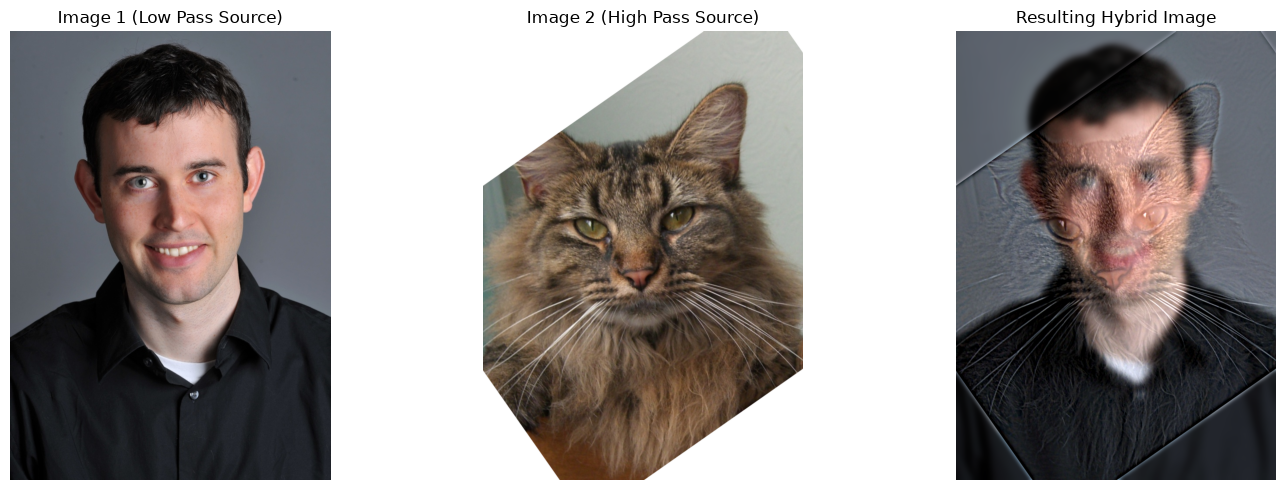

In [17]:
#2.2 Hybrid Images Nutmeg Derek Colored
import numpy as np
import matplotlib.pyplot as plt
import cv2

img1 = cv2.imread(
    r'C:\Users\Muhammad Muneeb\Desktop\Documents\Masters\SYDE 671\Assignment'
    r' 2\hybrid\DerekPicture.jpg'
)
img2 = cv2.imread(
    r'C:\Users\Muhammad Muneeb\Desktop\Documents\Masters\SYDE 671\Assignment'
    r' 2\hybrid\nutmeg.jpg'
)

img1 = cv2.cvtColor(img1, cv2.COLOR_BGR2RGB)
img2 = cv2.cvtColor(img2, cv2.COLOR_BGR2RGB)

sigma_low = 7
sigma_high = 5

angle_degrees = 35
scale_factor = 1.2
tx, ty = 70, 0

h, w = img1.shape[:2]

h_img2, w_img2 = img2.shape[:2]
img2_cropped = img2[
    int(h_img2 * 0.1) : int(h_img2 * 0.7), int(w_img2 * 0.2) : int(w_img2 * 0.8)
]
hc, wc = img2_cropped.shape[:2]

center = (wc // 2, hc // 2)
M = cv2.getRotationMatrix2D(center, angle_degrees, scale_factor)

dst_x = (w / 2) + tx
dst_y = (h / 2) + ty
M[0, 2] = dst_x - (M[0, 0] * center[0] + M[0, 1] * center[1])
M[1, 2] = dst_y - (M[1, 0] * center[0] + M[1, 1] * center[1])

img2_aligned = cv2.warpAffine(
    img2_cropped, M, (w, h), borderValue=(255, 255, 255)
)

low_freq = cv2.GaussianBlur(
    img1.astype(np.float32), (0, 0), sigmaX=sigma_low, sigmaY=sigma_low
)
blur_img2 = cv2.GaussianBlur(
    img2_aligned.astype(np.float32), (0, 0), sigmaX=sigma_high, sigmaY=sigma_high
)

high_freq = img2_aligned.astype(np.float32) - blur_img2

hybrid_img = low_freq + high_freq
hybrid_img = np.clip(hybrid_img, 0, 255).astype(np.uint8)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.title('Image 1 (Low Pass Source)')
plt.imshow(img1)
plt.axis('off')

plt.subplot(1, 3, 2)
plt.title('Image 2 (High Pass Source)')
plt.imshow(img2_aligned)
plt.axis('off')

plt.subplot(1, 3, 3)
plt.title('Resulting Hybrid Image')
plt.imshow(hybrid_img)
plt.axis('off')

plt.tight_layout()
plt.show()

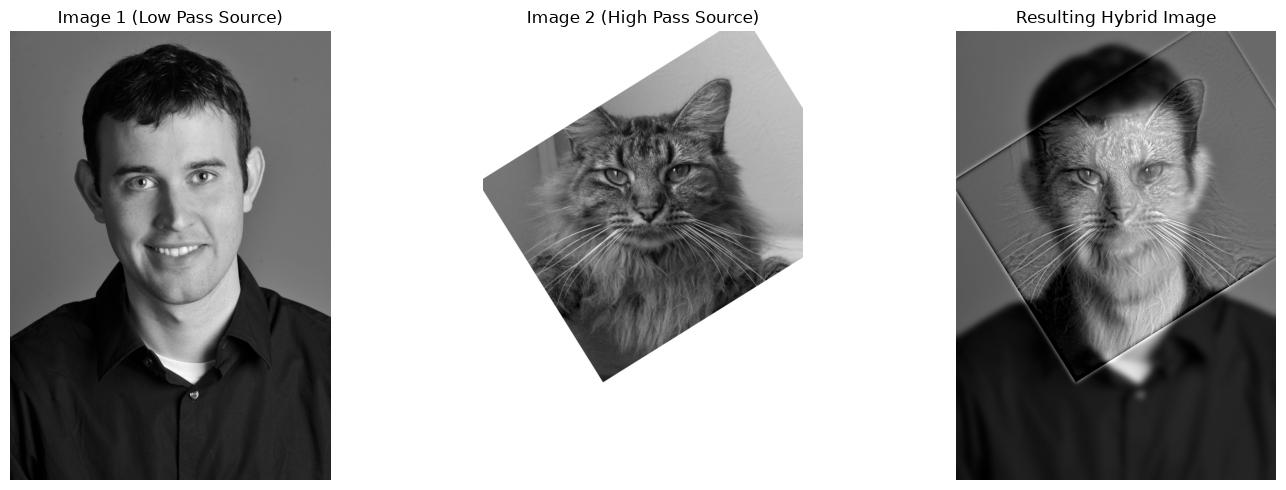

In [30]:
#2.2 Hybrid Images Nutmeg Derek Greyscale
import numpy as np
import matplotlib.pyplot as plt
import cv2

img1 = cv2.imread(
    r'C:\Users\Muhammad Muneeb\Desktop\Documents\Masters\SYDE 671\Assignment'
    r' 2\hybrid\DerekPicture.jpg'
)
img2 = cv2.imread(
    r'C:\Users\Muhammad Muneeb\Desktop\Documents\Masters\SYDE 671\Assignment'
    r' 2\hybrid\nutmeg.jpg'
)

img1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
img2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)

sigma_low = 7
sigma_high = 5

angle_degrees = 32
scale_factor = 0.85
tx, ty = 70, -130

h, w = img1.shape[:2]

h_img2, w_img2 = img2.shape[:2]
img2_cropped = img2[
    int(h_img2 * 0.1) : int(h_img2 * 0.7), int(w_img2 * 0.2) : int(w_img2 * 0.8)
]
hc, wc = img2_cropped.shape[:2]

center = (wc // 2, hc // 2)
M = cv2.getRotationMatrix2D(center, angle_degrees, scale_factor)

dst_x = (w / 2) + tx
dst_y = (h / 2) + ty
M[0, 2] = dst_x - (M[0, 0] * center[0] + M[0, 1] * center[1])
M[1, 2] = dst_y - (M[1, 0] * center[0] + M[1, 1] * center[1])

img2_aligned = cv2.warpAffine(
    img2_cropped, M, (w, h), borderValue=(255, 255, 255)
)

low_freq = cv2.GaussianBlur(
    img1.astype(np.float32), (0, 0), sigmaX=sigma_low, sigmaY=sigma_low
)
blur_img2 = cv2.GaussianBlur(
    img2_aligned.astype(np.float32), (0, 0), sigmaX=sigma_high, sigmaY=sigma_high
)

high_freq = img2_aligned.astype(np.float32) - blur_img2

hybrid_img = low_freq + high_freq
hybrid_img = np.clip(hybrid_img, 0, 255).astype(np.uint8)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.title('Image 1 (Low Pass Source)')
plt.imshow(img1, cmap="gray")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.title('Image 2 (High Pass Source)')
plt.imshow(img2_aligned, cmap="gray")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.title('Resulting Hybrid Image')
plt.imshow(hybrid_img, cmap="gray")
plt.axis('off')

plt.tight_layout()
plt.show()

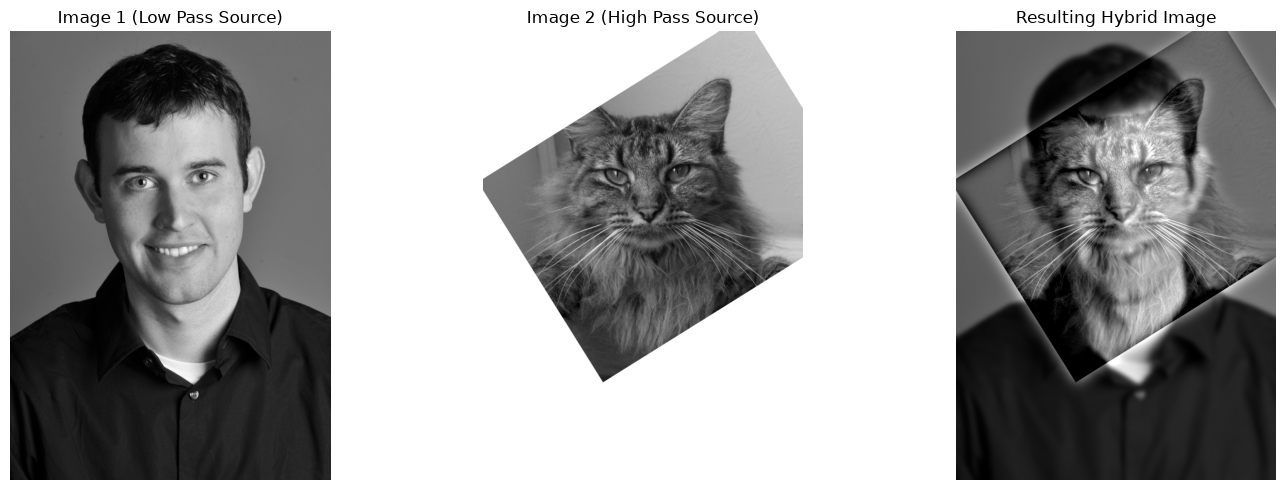

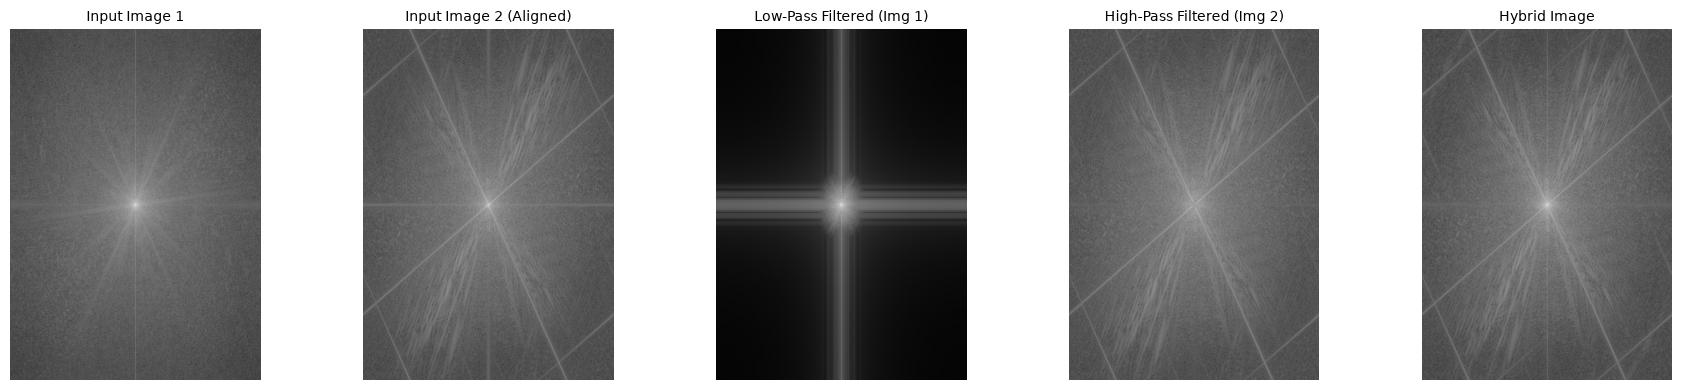

In [7]:
#2.2 Hybrid Images Nutmeg Derek Greyscale with Frquency analysis
import numpy as np
import matplotlib.pyplot as plt
import cv2

img1 = cv2.imread(
    r'C:\Users\Muhammad Muneeb\Desktop\Documents\Masters\SYDE 671\Assignment'
    r' 2\hybrid\DerekPicture.jpg'
)
img2 = cv2.imread(
    r'C:\Users\Muhammad Muneeb\Desktop\Documents\Masters\SYDE 671\Assignment'
    r' 2\hybrid\nutmeg.jpg'
)

img1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
img2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)

sigma_low = 5
sigma_high = 15

angle_degrees = 32
scale_factor = 0.85
tx, ty = 70, -130

h, w = img1.shape[:2]

h_img2, w_img2 = img2.shape[:2]
img2_cropped = img2[
    int(h_img2 * 0.1) : int(h_img2 * 0.7), int(w_img2 * 0.2) : int(w_img2 * 0.8)
]
hc, wc = img2_cropped.shape[:2]

center = (wc // 2, hc // 2)
M = cv2.getRotationMatrix2D(center, angle_degrees, scale_factor)

dst_x = (w / 2) + tx
dst_y = (h / 2) + ty
M[0, 2] = dst_x - (M[0, 0] * center[0] + M[0, 1] * center[1])
M[1, 2] = dst_y - (M[1, 0] * center[0] + M[1, 1] * center[1])

img2_aligned = cv2.warpAffine(
    img2_cropped, M, (w, h), borderValue=(255, 255, 255)
)

low_freq = cv2.GaussianBlur(
    img1.astype(np.float32), (0, 0), sigmaX=sigma_low, sigmaY=sigma_low
)
blur_img2 = cv2.GaussianBlur(
    img2_aligned.astype(np.float32), (0, 0), sigmaX=sigma_high, sigmaY=sigma_high
)

high_freq = img2_aligned.astype(np.float32) - blur_img2

hybrid_img = low_freq + high_freq
hybrid_img = np.clip(hybrid_img, 0, 255).astype(np.uint8)


plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.title('Image 1 (Low Pass Source)')
plt.imshow(img1, cmap="gray")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.title('Image 2 (High Pass Source)')
plt.imshow(img2_aligned, cmap="gray")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.title('Resulting Hybrid Image')
plt.imshow(hybrid_img, cmap="gray")
plt.axis('off')

plt.tight_layout()
plt.show()


images_to_transform = [
    ("Input Image 1", img1),
    ("Input Image 2 (Aligned)", img2_aligned),
    ("Low-Pass Filtered (Img 1)", low_freq),
    ("High-Pass Filtered (Img 2)", high_freq + 127), 
    ("Hybrid Image", hybrid_img)
]

plt.figure(figsize=(18, 4))
for i, (title, img) in enumerate(images_to_transform):
    f_transform = np.fft.fft2(img.astype(np.float32))
    f_shift = np.fft.fftshift(f_transform)
    log_magnitude = np.log(np.abs(f_shift) + 1)
    
    plt.subplot(1, 5, i + 1)
    plt.title(title, fontsize=10)
    plt.imshow(log_magnitude, cmap="gray")
    plt.axis('off')

plt.tight_layout()
plt.show()


--- Running Experiment 1: sigma_low = 4, sigma_high = 3 ---


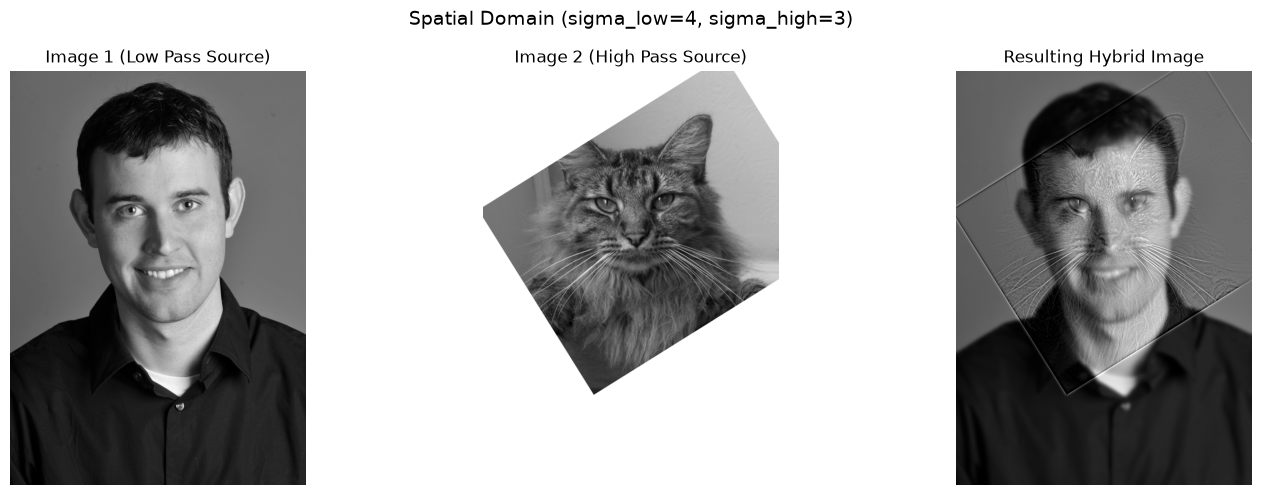

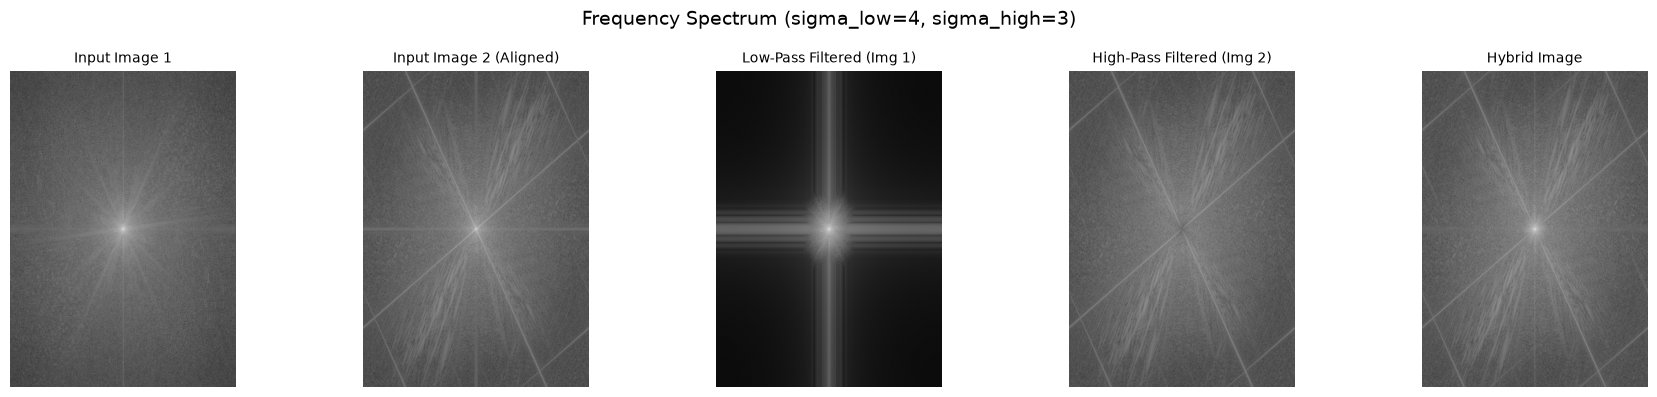


--- Running Experiment 2: sigma_low = 7, sigma_high = 5 ---


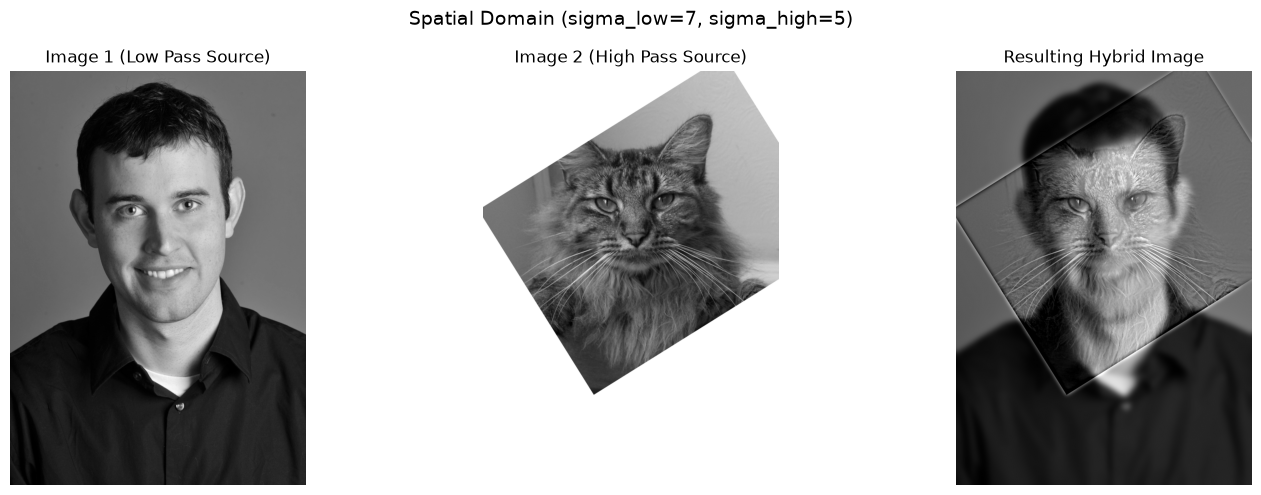

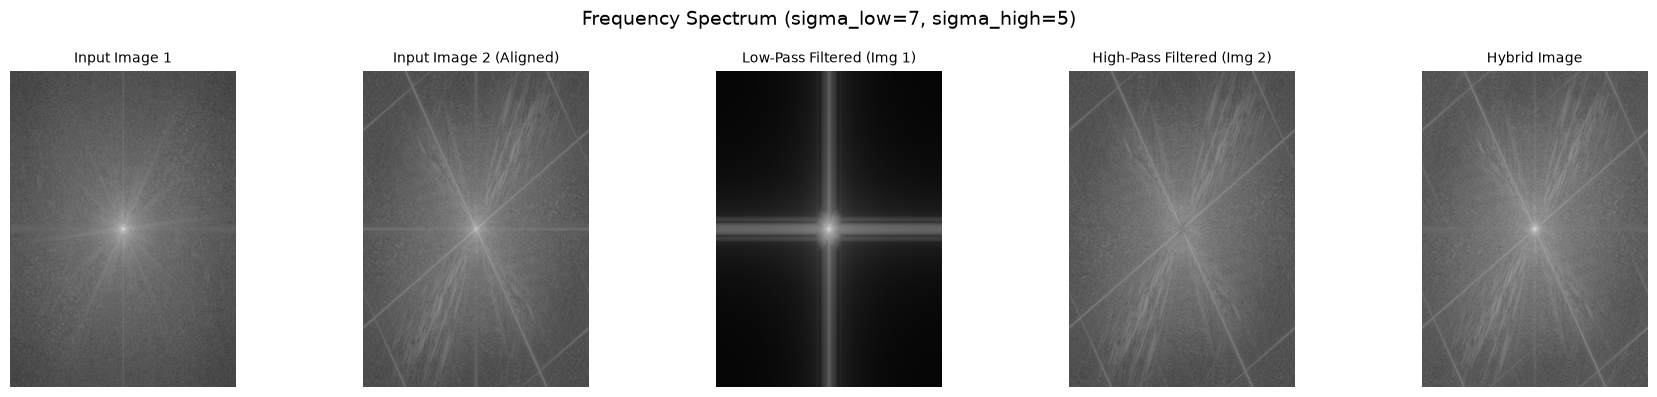


--- Running Experiment 3: sigma_low = 12, sigma_high = 8 ---


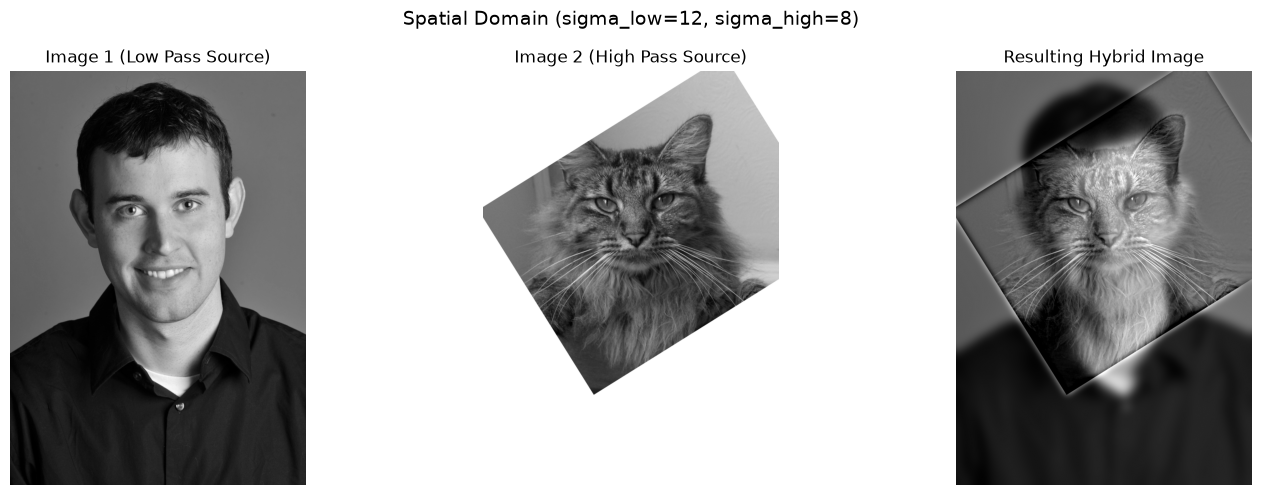

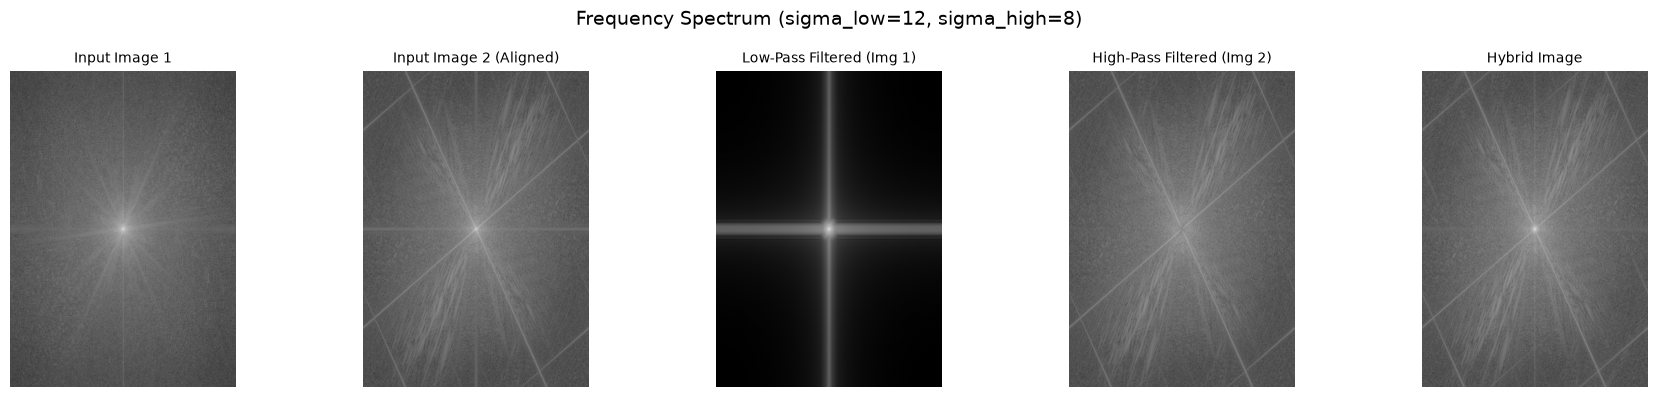

In [8]:
#2.2 Hybrid Images Nutmeg Derek Greyscale with Sigma Parameter Loop
import numpy as np
import matplotlib.pyplot as plt
import cv2

img1 = cv2.imread(
    r'C:\Users\Muhammad Muneeb\Desktop\Documents\Masters\SYDE 671\Assignment'
    r' 2\hybrid\DerekPicture.jpg'
)
img2 = cv2.imread(
    r'C:\Users\Muhammad Muneeb\Desktop\Documents\Masters\SYDE 671\Assignment'
    r' 2\hybrid\nutmeg.jpg'
)

img1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
img2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)

angle_degrees = 32
scale_factor = 0.85
tx, ty = 70, -130

h, w = img1.shape[:2]
h_img2, w_img2 = img2.shape[:2]
img2_cropped = img2[
    int(h_img2 * 0.1) : int(h_img2 * 0.7), int(w_img2 * 0.2) : int(w_img2 * 0.8)
]
hc, wc = img2_cropped.shape[:2]

center = (wc // 2, hc // 2)
M = cv2.getRotationMatrix2D(center, angle_degrees, scale_factor)

dst_x = (w / 2) + tx
dst_y = (h / 2) + ty
M[0, 2] = dst_x - (M[0, 0] * center[0] + M[0, 1] * center[1])
M[1, 2] = dst_y - (M[1, 0] * center[0] + M[1, 1] * center[1])

img2_aligned = cv2.warpAffine(
    img2_cropped, M, (w, h), borderValue=(255, 255, 255)
)

sigma_experiments = [
    (4, 3),
    (7, 5),
    (12, 8)
]

for idx, (sigma_low, sigma_high) in enumerate(sigma_experiments):
    print(f"\n--- Running Experiment {idx + 1}: sigma_low = {sigma_low}, sigma_high = {sigma_high} ---")
    
    low_freq = cv2.GaussianBlur(
        img1.astype(np.float32), (0, 0), sigmaX=sigma_low, sigmaY=sigma_low
    )
    blur_img2 = cv2.GaussianBlur(
        img2_aligned.astype(np.float32), (0, 0), sigmaX=sigma_high, sigmaY=sigma_high
    )

    high_freq = img2_aligned.astype(np.float32) - blur_img2

    hybrid_img = low_freq + high_freq
    hybrid_img = np.clip(hybrid_img, 0, 255).astype(np.uint8)

    plt.figure(figsize=(15, 5))
    plt.suptitle(f"Spatial Domain (sigma_low={sigma_low}, sigma_high={sigma_high})", fontsize=14)

    plt.subplot(1, 3, 1)
    plt.title('Image 1 (Low Pass Source)')
    plt.imshow(img1, cmap="gray")
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.title('Image 2 (High Pass Source)')
    plt.imshow(img2_aligned, cmap="gray")
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.title('Resulting Hybrid Image')
    plt.imshow(hybrid_img, cmap="gray")
    plt.axis('off')

    plt.tight_layout()
    plt.show()

    images_to_transform = [
        ("Input Image 1", img1),
        ("Input Image 2 (Aligned)", img2_aligned),
        ("Low-Pass Filtered (Img 1)", low_freq),
        ("High-Pass Filtered (Img 2)", high_freq + 127), 
        ("Hybrid Image", hybrid_img)
    ]

    plt.figure(figsize=(18, 4))
    plt.suptitle(f"Frequency Spectrum (sigma_low={sigma_low}, sigma_high={sigma_high})", fontsize=14)
    
    for i, (title, img) in enumerate(images_to_transform):
        f_transform = np.fft.fft2(img.astype(np.float32))
        f_shift = np.fft.fftshift(f_transform)
        log_magnitude = np.log(np.abs(f_shift) + 1)
        
        plt.subplot(1, 5, i + 1)
        plt.title(title, fontsize=10)
        plt.imshow(log_magnitude, cmap="gray")
        plt.axis('off')

    plt.tight_layout()
    plt.show()

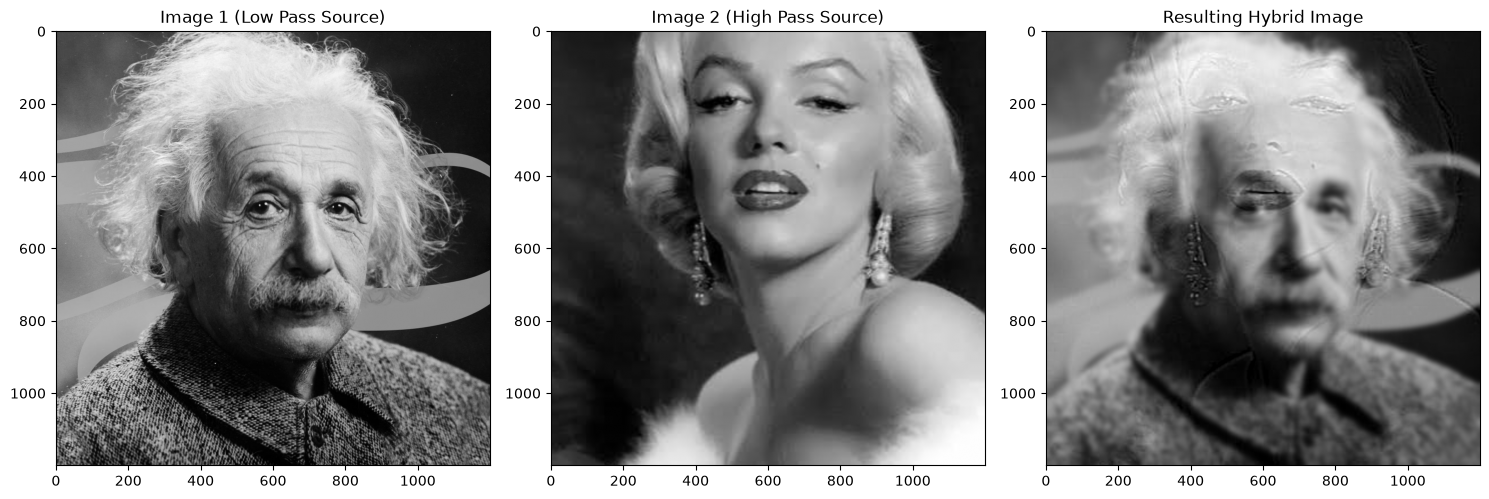

In [1]:
#2.2 Hybrid Images Merilyn Einstein
import numpy as np
import matplotlib.pyplot as plt
import cv2

img1 = cv2.imread(r"C:\Users\Muhammad Muneeb\Desktop\Documents\Masters\SYDE 671\Assignment 2\hybrid\Albert-Einstein.jpg")
img2 = cv2.imread(r"C:\Users\Muhammad Muneeb\Desktop\Documents\Masters\SYDE 671\Assignment 2\hybrid\merilyn.jpg")

img1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
img2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)

sigma_low = 7
sigma_high = 5

angle_degrees = 0
scale_factor = 3.15
tx, ty = 0, 0     

h, w = img1.shape[:2]

h_img2, w_img2 = img2.shape[:2]

img2_cropped = img2[
    int(h_img2 * 0.0) : int(h_img2 * 1.0), int(w_img2 * 0.0) : int(w_img2 * 1.0)
]
hc, wc = img2_cropped.shape[:2]

center = (wc // 2, hc // 2)
M = cv2.getRotationMatrix2D(center, angle_degrees, scale_factor)

dst_x = (w / 2) + tx
dst_y = (h / 2) + ty
M[0, 2] = dst_x - (M[0, 0] * center[0] + M[0, 1] * center[1])
M[1, 2] = dst_y - (M[1, 0] * center[0] + M[1, 1] * center[1])

img2_aligned = cv2.warpAffine(
    img2_cropped, M, (w, h), borderValue=(255, 255, 255)
)

low_freq = cv2.GaussianBlur(
    img1.astype(np.float32), (0, 0), sigmaX=sigma_low, sigmaY=sigma_low
)
blur_img2 = cv2.GaussianBlur(
    img2_aligned.astype(np.float32), (0, 0), sigmaX=sigma_high, sigmaY=sigma_high
)

high_freq = img2_aligned.astype(np.float32) - blur_img2

hybrid_img = low_freq + high_freq
hybrid_img = np.clip(hybrid_img, 0, 255).astype(np.uint8)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.title('Image 1 (Low Pass Source)')
plt.imshow(img1, cmap="gray")
plt.axis('on')

plt.subplot(1, 3, 2)
plt.title('Image 2 (High Pass Source)')
plt.imshow(img2_aligned, cmap="gray")
plt.axis('on')

plt.subplot(1, 3, 3)
plt.title('Resulting Hybrid Image')
plt.imshow(hybrid_img, cmap="gray")
plt.axis('on')

plt.tight_layout()
plt.show()

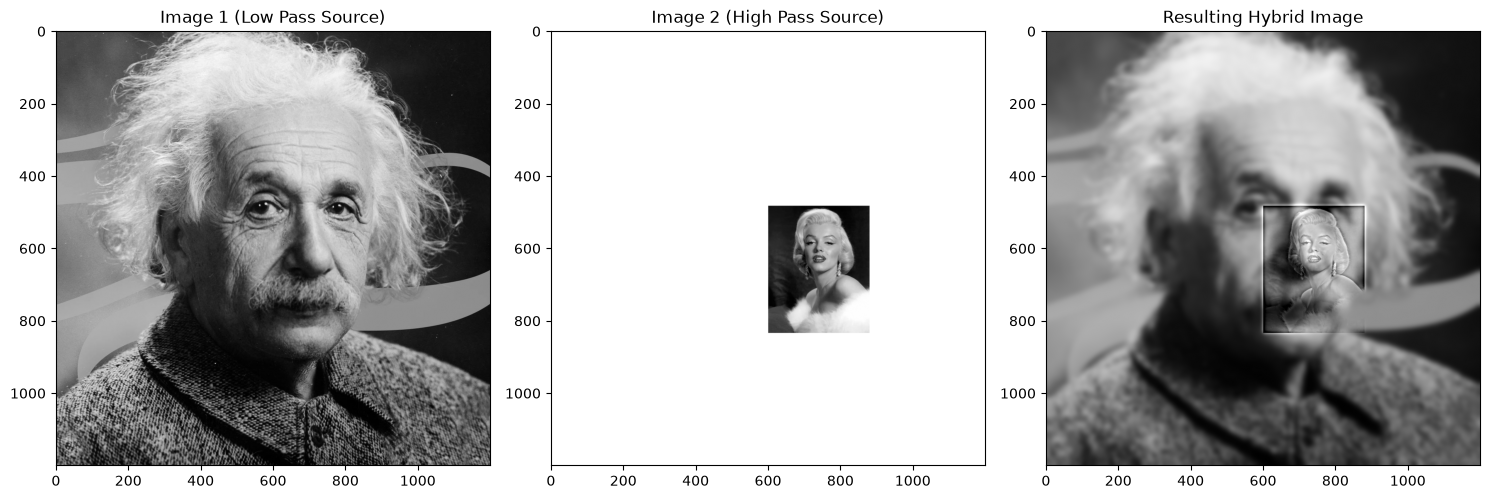

In [4]:
#2.2 Hybrid Images Merilyn Einstein Landmark-Based
import numpy as np
import matplotlib.pyplot as plt
import cv2

img1 = cv2.imread(r"C:\Users\Muhammad Muneeb\Desktop\Documents\Masters\SYDE 671\Assignment 2\hybrid\Albert-Einstein.jpg")
img2 = cv2.imread(r"C:\Users\Muhammad Muneeb\Desktop\Documents\Masters\SYDE 671\Assignment 2\hybrid\merilyn.jpg")

img1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
img2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)

sigma_low = 7
sigma_high = 5

h1, w1 = img1.shape[:2]
h2, w2 = img2.shape[:2]

# --- ENTER YOUR LANDMARK COORDINATES HERE (x, y) ---
# Tip: Find the (x, y) pixel coordinates of the left and right eyes 
# for each image (e.g., using an image viewer or matplotlib plot).
pts1 = np.array([
    [580, 510],  # Einstein: Left Eye (x, y)
    [790, 510]   # Einstein: Right Eye (x, y)
], dtype=np.float32)

pts2 = np.array([
    [440, 205],  # Marilyn: Left Eye (x, y)
    [810, 205]   # Marilyn: Right Eye (x, y)
], dtype=np.float32)

# Compute centers of the reference points
cx1, cy1 = np.mean(pts1, axis=0)
cx2, cy2 = np.mean(pts2, axis=0)

# Compute scale difference based on distance between the two points
len1 = np.sqrt(np.sum((pts1[1] - pts1[0])**2))
len2 = np.sqrt(np.sum((pts2[1] - pts2[0])**2))
scale_factor = len1 / len2

# Rotation angle between point pairs (usually 0 if both portraits are upright)
angle_degrees = 0

# Set up affine transformation matrix based on landmarks
center = (cx2, cy2)
M = cv2.getRotationMatrix2D(center, angle_degrees, scale_factor)

# Adjust translation component so that point centers align with target centers plus canvas shift
dst_x = cx1
dst_y = cy1
M[0, 2] += dst_x - M[0, 0] * center[0] - M[0, 1] * center[1]
M[1, 2] += dst_y - M[1, 0] * center[0] - M[1, 1] * center[1]

# Warp Image 2 to align with Image 1 dimensions and layout
img2_aligned = cv2.warpAffine(
    img2, M, (w1, h1), borderValue=255
)

# Frequency filtering following Oliva et al. methodology
low_freq = cv2.GaussianBlur(
    img1.astype(np.float32), (0, 0), sigmaX=sigma_low, sigmaY=sigma_low
)
blur_img2 = cv2.GaussianBlur(
    img2_aligned.astype(np.float32), (0, 0), sigmaX=sigma_high, sigmaY=sigma_high
)

high_freq = img2_aligned.astype(np.float32) - blur_img2

hybrid_img = low_freq + high_freq
hybrid_img = np.clip(hybrid_img, 0, 255).astype(np.uint8)

# Visualization
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.title('Image 1 (Low Pass Source)')
plt.imshow(img1, cmap="gray")
plt.axis('on')

plt.subplot(1, 3, 2)
plt.title('Image 2 (High Pass Source)')
plt.imshow(img2_aligned, cmap="gray")
plt.axis('on')

plt.subplot(1, 3, 3)
plt.title('Resulting Hybrid Image')
plt.imshow(hybrid_img, cmap="gray")
plt.axis('on')

plt.tight_layout()
plt.show()

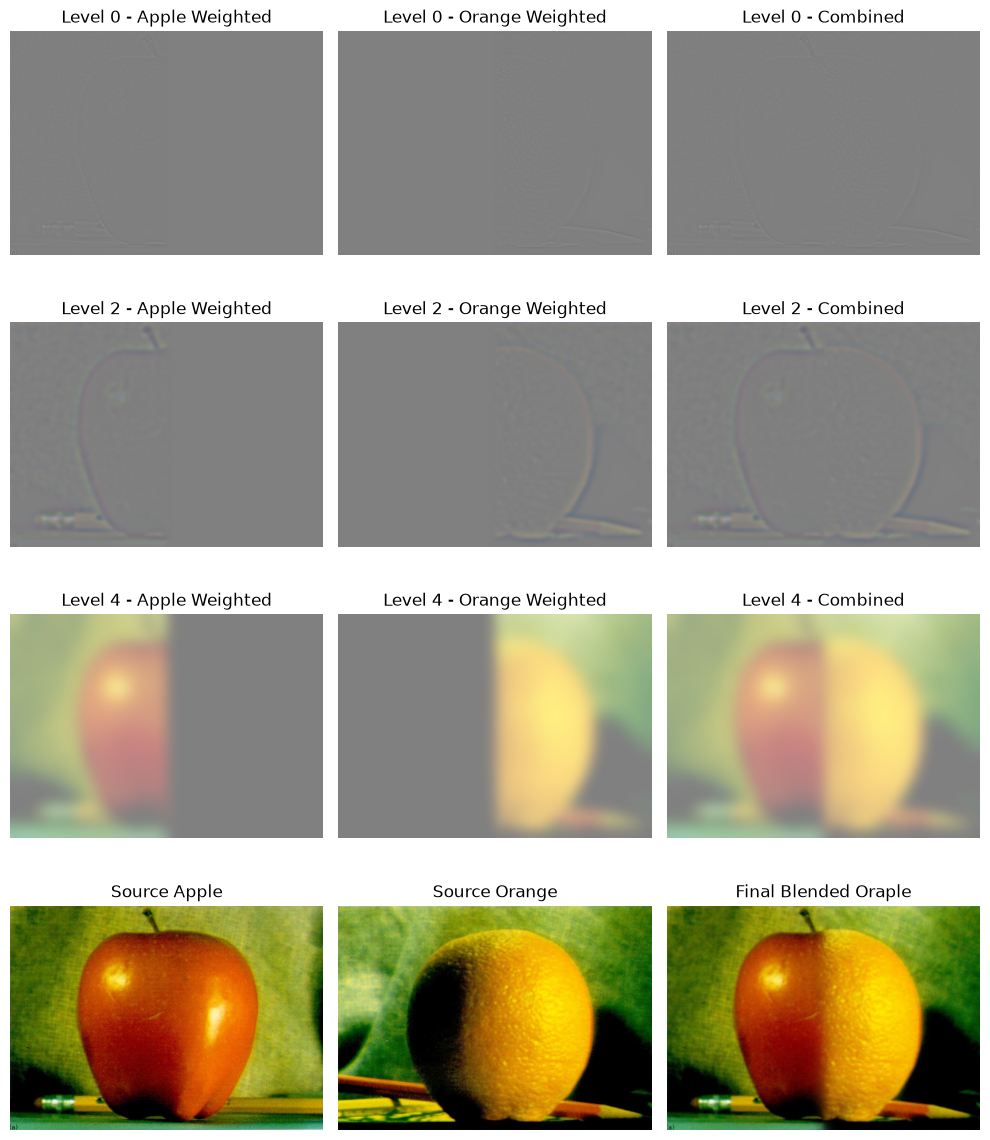

In [13]:
#Laplacian Pyramid Blending Breakdown (Burt and Adelson Style)
import cv2
import matplotlib.pyplot as plt
import numpy as np

img1 = cv2.imread(r"C:\Users\Muhammad Muneeb\Desktop\Documents\Masters\SYDE 671\Assignment 2\ass2 part 2 images\burt_apple.png")
img2 = cv2.imread(r"C:\Users\Muhammad Muneeb\Desktop\Documents\Masters\SYDE 671\Assignment 2\ass2 part 2 images\burt_orange.png")

img1 = cv2.cvtColor(img1, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
img2 = cv2.cvtColor(img2, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0

if img1.shape != img2.shape:
    img2 = cv2.resize(img2, (img1.shape[1], img1.shape[0]))

h, w = img1.shape[:2]

mask = np.zeros((h, w), dtype=np.float32)
mask[:, :w // 2] = 1.0

def build_gaussian_stack(image, num_levels=5, base_sigma=2.0):
    stack = []
    for i in range(num_levels):
        sigma = base_sigma * (2 ** i)
        blurred = cv2.GaussianBlur(image, (0, 0), sigmaX=sigma, sigmaY=sigma)
        stack.append(blurred)
    return stack

def build_laplacian_stack(g_stack):
    stack = []
    for i in range(len(g_stack) - 1):
        stack.append(g_stack[i] - g_stack[i+1])
    stack.append(g_stack[-1])
    return stack

num_levels = 5
base_sigma = 1

g_stack1 = build_gaussian_stack(img1, num_levels, base_sigma)
g_stack2 = build_gaussian_stack(img2, num_levels, base_sigma)
g_mask   = build_gaussian_stack(mask, num_levels, base_sigma)

l_stack1 = build_laplacian_stack(g_stack1)
l_stack2 = build_laplacian_stack(g_stack2)

blended_l_stack = []
apple_contribs = []
orange_contribs = []

for l1, l2, gm in zip(l_stack1, l_stack2, g_mask):
    gm_3c = np.stack([gm, gm, gm], axis=-1)
    ac = gm_3c * l1
    oc = (1.0 - gm_3c) * l2
    apple_contribs.append(ac)
    orange_contribs.append(oc)
    blended_level = ac + oc
    blended_l_stack.append(blended_level)

oraple_img = np.sum(blended_l_stack, axis=0)
oraple_img_clipped = np.clip(oraple_img * 255.0, 0, 255).astype(np.uint8)

levels_to_show = [0, 2, 4]
fig, axes = plt.subplots(len(levels_to_show) + 1, 3, figsize=(10, 12))

for row_idx, lvl in enumerate(levels_to_show):
    ac_disp = np.clip(apple_contribs[lvl] * 128.0 + 128.0, 0, 255).astype(np.uint8)
    oc_disp = np.clip(orange_contribs[lvl] * 128.0 + 128.0, 0, 255).astype(np.uint8)
    bl_disp = np.clip(blended_l_stack[lvl] * 128.0 + 128.0, 0, 255).astype(np.uint8)

    axes[row_idx, 0].imshow(ac_disp)
    axes[row_idx, 0].set_title(f"Level {lvl} - Apple Weighted")
    axes[row_idx, 0].axis('off')

    axes[row_idx, 1].imshow(oc_disp)
    axes[row_idx, 1].set_title(f"Level {lvl} - Orange Weighted")
    axes[row_idx, 1].axis('off')

    axes[row_idx, 2].imshow(bl_disp)
    axes[row_idx, 2].set_title(f"Level {lvl} - Combined")
    axes[row_idx, 2].axis('off')

axes[-1, 0].imshow((img1 * 255).astype(np.uint8))
axes[-1, 0].set_title("Source Apple")
axes[-1, 0].axis('off')

axes[-1, 1].imshow((img2 * 255).astype(np.uint8))
axes[-1, 1].set_title("Source Orange")
axes[-1, 1].axis('off')

axes[-1, 2].imshow(oraple_img_clipped)
axes[-1, 2].set_title("Final Blended Oraple")
axes[-1, 2].axis('off')

plt.tight_layout()
plt.show()

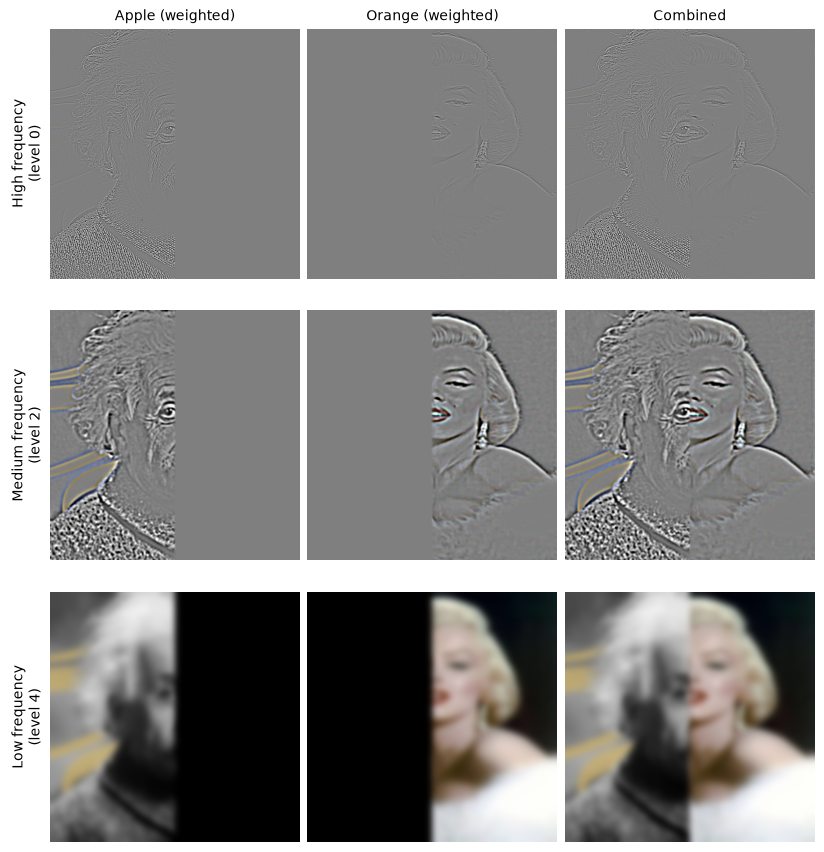

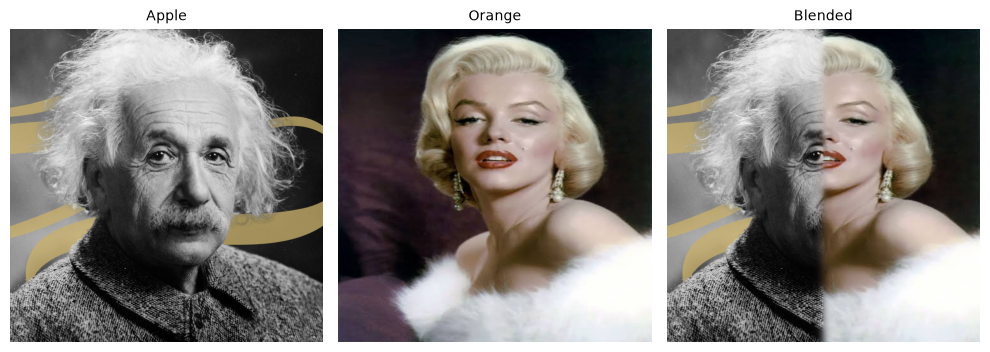

In [20]:
# Laplacian Pyramid Blending (Burt & Adelson style) using Gaussian/Laplacian stacks
import cv2
import matplotlib.pyplot as plt
import numpy as np

path = r"C:\Users\Muhammad Muneeb\Desktop\Documents\Masters\SYDE 671\Assignment 2\hybrid"
img1 = cv2.imread(path + r"\Albert-Einstein.jpg")
img2 = cv2.imread(path + r"\merilyn.jpg")

img1 = cv2.cvtColor(img1, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
img2 = cv2.cvtColor(img2, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0

if img1.shape != img2.shape:
    img2 = cv2.resize(img2, (img1.shape[1], img1.shape[0]))

h, w = img1.shape[:2]

mask = np.zeros((h, w), dtype=np.float32)
mask[:, :w // 2] = 1.0


def build_gaussian_stack(image, num_levels=5, base_sigma=2.0):
    stack = [image.copy()]
    for i in range(1, num_levels):
        sigma = base_sigma * (2 ** (i - 1))
        stack.append(cv2.GaussianBlur(image, (0, 0), sigmaX=sigma, sigmaY=sigma))
    return stack


def build_laplacian_stack(g_stack):
    stack = [g_stack[i] - g_stack[i + 1] for i in range(len(g_stack) - 1)]
    stack.append(g_stack[-1])
    return stack


num_levels = 5
base_sigma = 2.0

g1 = build_gaussian_stack(img1, num_levels, base_sigma)
g2 = build_gaussian_stack(img2, num_levels, base_sigma)
gm = build_gaussian_stack(mask, num_levels, base_sigma)

l1 = build_laplacian_stack(g1)
l2 = build_laplacian_stack(g2)

apple_contribs, orange_contribs, blended_stack = [], [], []
for a, o, m in zip(l1, l2, gm):
    m3 = np.dstack([m, m, m])
    ac = m3 * a
    oc = (1.0 - m3) * o
    apple_contribs.append(ac)
    orange_contribs.append(oc)
    blended_stack.append(ac + oc)

assert np.allclose(sum(l1), img1, atol=1e-4)
assert np.allclose(sum(l2), img2, atol=1e-4)

blend = np.clip(np.sum(blended_stack, axis=0), 0, 1)


def to_display(img, gain, is_residual):
    if is_residual:
        return np.clip(img, 0, 1)
    return np.clip(0.5 + gain * img, 0, 1)


levels_to_show = [0, 2, 4]
row_labels = ["High frequency\n(level 0)", "Medium frequency\n(level 2)", "Low frequency\n(level 4)"]
col_labels = ["Apple (weighted)", "Orange (weighted)", "Combined"]

fig, axes = plt.subplots(3, 3, figsize=(9, 9))
fig.subplots_adjust(left=0.14, right=0.99, top=0.94, bottom=0.01, wspace=0.03, hspace=0.03)

for r, lvl in enumerate(levels_to_show):
    is_res = (lvl == num_levels - 1)
    peak = max(np.percentile(np.abs(x[lvl]), 99.5)
               for x in (apple_contribs, orange_contribs, blended_stack))
    gain = 0.5 / max(peak, 1e-6)

    for c, stack in enumerate((apple_contribs, orange_contribs, blended_stack)):
        ax = axes[r, c]
        ax.imshow(to_display(stack[lvl], gain, is_res))
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)
        if r == 0:
            ax.set_title(col_labels[c], fontsize=10)
        if c == 0:
            ax.set_ylabel(row_labels[r], fontsize=10)

plt.show()

fig2, ax2 = plt.subplots(1, 3, figsize=(10, 4))
for ax, im, t in zip(ax2, (img1, img2, blend), ("Apple", "Orange", "Blended")):
    ax.imshow(im)
    ax.set_title(t, fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

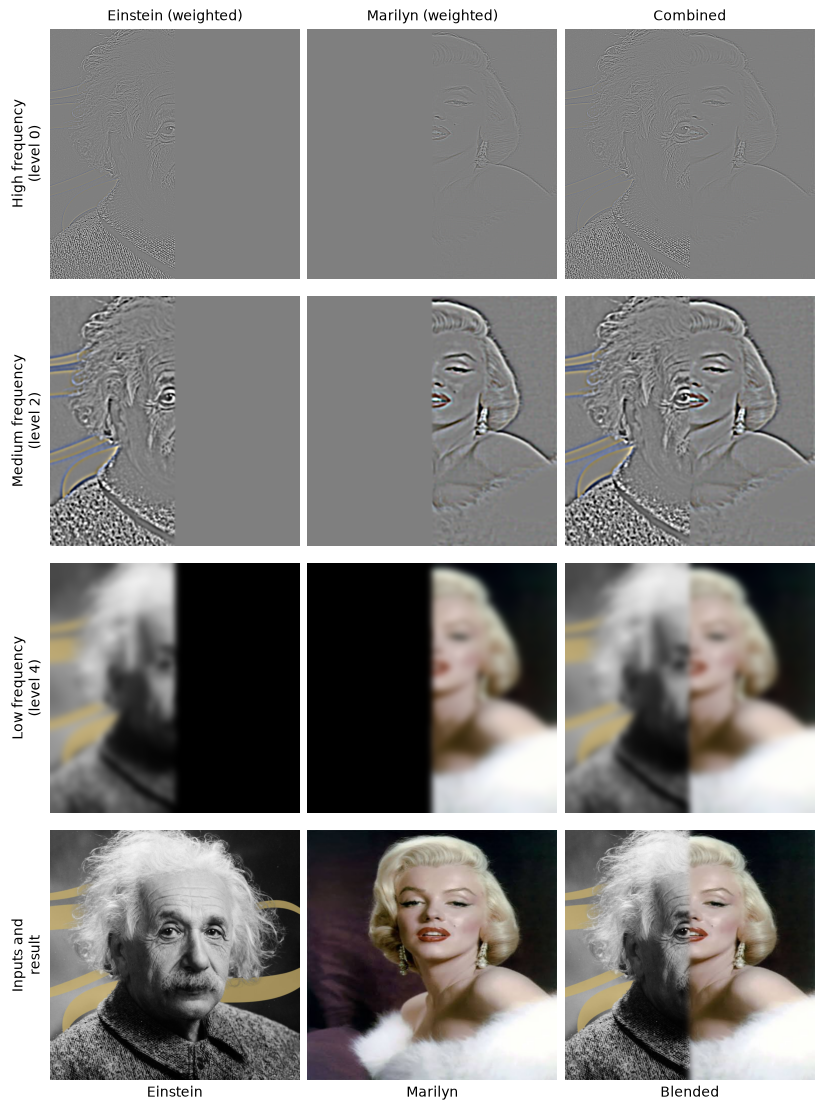

In [22]:
# Laplacian Pyramid Blending (Burt & Adelson style) using Gaussian/Laplacian stacks
import cv2
import matplotlib.pyplot as plt
import numpy as np

path = r"C:\Users\Muhammad Muneeb\Desktop\Documents\Masters\SYDE 671\Assignment 2\hybrid"
img1 = cv2.imread(path + r"\Albert-Einstein.jpg")
img2 = cv2.imread(path + r"\merilyn.jpg")

img1 = cv2.cvtColor(img1, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
img2 = cv2.cvtColor(img2, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0

if img1.shape != img2.shape:
    img2 = cv2.resize(img2, (img1.shape[1], img1.shape[0]))

h, w = img1.shape[:2]

mask = np.zeros((h, w), dtype=np.float32)
mask[:, :w // 2] = 1.0


def build_gaussian_stack(image, num_levels=5, base_sigma=2.0):
    stack = [image.copy()]
    for i in range(1, num_levels):
        sigma = base_sigma * (2 ** (i - 1))
        stack.append(cv2.GaussianBlur(image, (0, 0), sigmaX=sigma, sigmaY=sigma))
    return stack


def build_laplacian_stack(g_stack):
    stack = [g_stack[i] - g_stack[i + 1] for i in range(len(g_stack) - 1)]
    stack.append(g_stack[-1])
    return stack


num_levels = 5
base_sigma = 2.0

g1 = build_gaussian_stack(img1, num_levels, base_sigma)
g2 = build_gaussian_stack(img2, num_levels, base_sigma)
gm = build_gaussian_stack(mask, num_levels, base_sigma)

l1 = build_laplacian_stack(g1)
l2 = build_laplacian_stack(g2)

img1_contribs, img2_contribs, blended_stack = [], [], []
for a, o, m in zip(l1, l2, gm):
    m3 = np.dstack([m, m, m])
    ac = m3 * a
    oc = (1.0 - m3) * o
    img1_contribs.append(ac)
    img2_contribs.append(oc)
    blended_stack.append(ac + oc)

assert np.allclose(sum(l1), img1, atol=1e-4)
assert np.allclose(sum(l2), img2, atol=1e-4)

blend = np.clip(np.sum(blended_stack, axis=0), 0, 1)


def to_display(img, gain, is_residual):
    if is_residual:
        return np.clip(img, 0, 1)
    return np.clip(0.5 + gain * img, 0, 1)


def clean_axis(ax):
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)


levels_to_show = [0, 2, 4]
row_labels = ["High frequency\n(level 0)", "Medium frequency\n(level 2)", "Low frequency\n(level 4)"]
col_labels = ["Einstein (weighted)", "Marilyn (weighted)", "Combined"]
bottom_labels = ["Einstein", "Marilyn", "Blended"]

left, right, top, bottom = 0.14, 0.99, 0.95, 0.05
fig_w = 9
cell_w = fig_w * (right - left) / 3
fig_h = (cell_w * h / w * 4) / (top - bottom) * 1.04

fig = plt.figure(figsize=(fig_w, fig_h))
gs = fig.add_gridspec(4, 3, left=left, right=right, top=top, bottom=bottom,
                      wspace=0.03, hspace=0.03)

for r, lvl in enumerate(levels_to_show):
    is_res = (lvl == num_levels - 1)
    peak = max(np.percentile(np.abs(x[lvl]), 99.5)
               for x in (img1_contribs, img2_contribs, blended_stack))
    gain = 0.5 / max(peak, 1e-6)

    for c, stack in enumerate((img1_contribs, img2_contribs, blended_stack)):
        ax = fig.add_subplot(gs[r, c])
        ax.imshow(to_display(stack[lvl], gain, is_res))
        clean_axis(ax)
        if r == 0:
            ax.set_title(col_labels[c], fontsize=10)
        if c == 0:
            ax.set_ylabel(row_labels[r], fontsize=10)

for c, (im, t) in enumerate(zip((img1, img2, blend), bottom_labels)):
    ax = fig.add_subplot(gs[3, c])
    ax.imshow(im)
    clean_axis(ax)
    ax.set_xlabel(t, fontsize=10)
    if c == 0:
        ax.set_ylabel("Inputs and\nresult", fontsize=10)

plt.show()
